# Session 5: CNN on MNIST and YOLOv8

This notebook contains structured tasks for building a CNN on MNIST and experimenting with Ultralytics YOLOv8 (pretrained inference and a short training example).

**Instructions:**
- Complete all tasks directly in this notebook.
- Keep your code clear and well-commented.
- Use `%matplotlib inline` for visualizations.
- If you need to install packages (e.g., `ultralytics`), use `%pip` in a cell.
- When using external datasets, do NOT upload them to GitHub.

### ***DO NOT UPLOAD LARGE DATASETS OR MODEL WEIGHTS TO GITHUB***
<hr>

## Task 1: Convolutional Neural Network on MNIST — Build, Train, Evaluate, Visualize
Train a simple CNN on the MNIST handwritten digits dataset. After training, generate predictions on the test set, compare them to ground truth labels, and visualize a few results.

**Why this matters:**
- MNIST is a classic entry point for image classification and CNNs.
- You will practice the full workflow: data loading, model definition, training, evaluation, and visualization.

**Steps:**
- Load MNIST with appropriate transforms (normalize).
- Define a small CNN (Conv → ReLU → Pool → FC).
- Train for a few epochs (2–3 for demo).
- Evaluate on the test set and compute accuracy.
- Visualize several test images with predicted and true labels.

**Hint:** Use `torchvision.datasets.MNIST`, `DataLoader`, `nn.Conv2d`, `nn.ReLU`, `nn.MaxPool2d`, and `nn.CrossEntropyLoss`.

In [1]:
# TODO: Setup environment and imports
# - Import torch, torchvision, numpy, matplotlib
# - Set random seeds and select device (cpu/cuda)
# - Enable %matplotlib inline if needed
%matplotlib inline

import torch
import torch.nn as nn
import torch.optim as optim

import torchvision
from torchvision import datasets, transforms

import numpy as np
import matplotlib.pyplot as plt

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Select CPU or GPU
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

Using device: cpu


In [2]:
# TODO: Load MNIST train/test datasets and create DataLoaders
# - Apply ToTensor and Normalize transforms
# - Create train_loader and test_loader
# Define transformations
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

# Load training dataset
train_dataset = datasets.MNIST(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

# Load testing dataset
test_dataset = datasets.MNIST(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

# Create DataLoaders
train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))

100.0%
100.0%
100.0%
100.0%

Training samples: 60000
Testing samples: 10000


In [3]:
# TODO: Define a small CNN suitable for MNIST (1x28x28 input)
# - Use Conv2d, ReLU, MaxPool2d, Linear layers
# - Return logits for 10 classes
class MNIST_CNN(nn.Module):

    def __init__(self):
        super(MNIST_CNN, self).__init__()

        # First convolutional layer
        self.conv1 = nn.Conv2d(
            in_channels=1,
            out_channels=16,
            kernel_size=3
        )

        self.relu = nn.ReLU()

        # Max pooling
        self.pool = nn.MaxPool2d(kernel_size=2)

        # Second convolutional layer
        self.conv2 = nn.Conv2d(
            in_channels=16,
            out_channels=32,
            kernel_size=3
        )

        # Fully connected layers
        self.fc1 = nn.Linear(32 * 5 * 5, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):

        # First convolution
        x = self.relu(self.conv1(x))
        x = self.pool(x)

        # Second convolution
        x = self.relu(self.conv2(x))
        x = self.pool(x)

        # Flatten
        x = x.view(x.size(0), -1)

        # Fully connected layers
        x = self.relu(self.fc1(x))
        x = self.fc2(x)

        return x


# Create model
model = MNIST_CNN().to(device)

print(model)

MNIST_CNN(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1))
  (relu): ReLU()
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1))
  (fc1): Linear(in_features=800, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [4]:
# TODO: Set up optimizer and loss function
# - Choose Adam/SGD and CrossEntropyLoss
# Classification loss
criterion = nn.CrossEntropyLoss()

# Adam optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)
# TODO: Implement a short training loop (2–3 epochs)
# - Print loss/accuracy per epoch
epochs = 3

for epoch in range(epochs):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update model weights
        optimizer.step()

        running_loss += loss.item()

        # Get predicted classes
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Loss: {running_loss / len(train_loader):.4f} "
        f"Accuracy: {accuracy:.2f}%"
    )

Epoch [1/3] Loss: 0.1733 Accuracy: 94.82%
Epoch [2/3] Loss: 0.0513 Accuracy: 98.40%
Epoch [3/3] Loss: 0.0350 Accuracy: 98.90%


In [5]:
# TODO: Evaluate on the test set and compute accuracy
# - Switch model to eval mode
# - Accumulate correct predictions and total
model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Forward pass
        outputs = model(images)

        # Get predictions
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

# Calculate test accuracy
test_accuracy = 100 * correct / total

print(f"Test Accuracy: {test_accuracy:.2f}%")

Test Accuracy: 98.95%


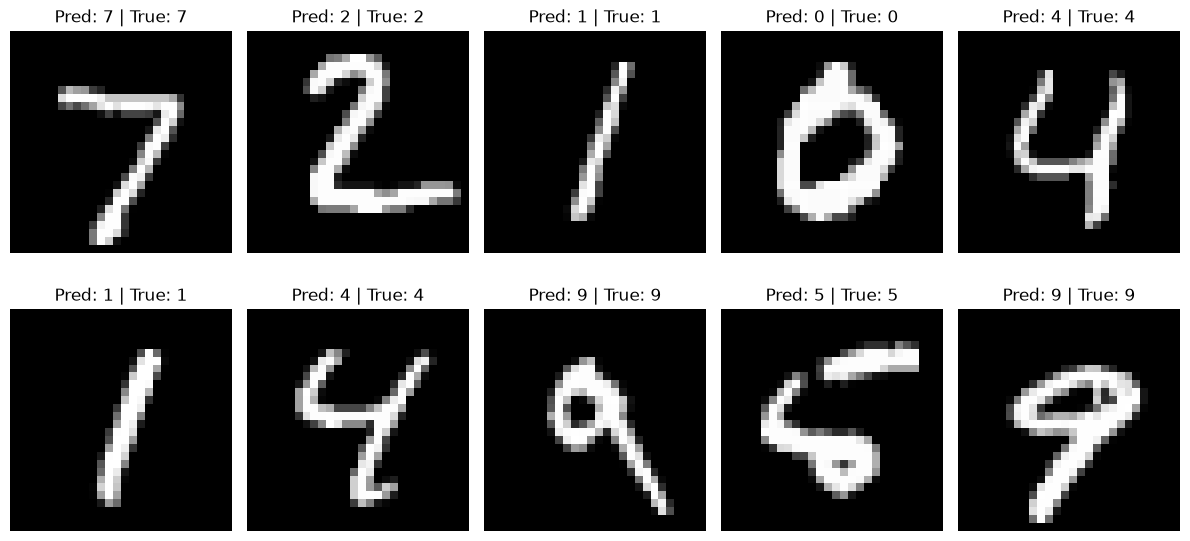

In [6]:
# TODO: Visualize a few test images with predicted and true labels
# - Sample a batch from test_loader
# - Run model and plot images with 'pred vs true' titles
# Get one batch from test dataset
images, labels = next(iter(test_loader))

images = images.to(device)

model.eval()

with torch.no_grad():
    outputs = model(images)
    _, predictions = torch.max(outputs, 1)

# Move data to CPU for visualization
images = images.cpu()
predictions = predictions.cpu()

# Display first 10 images
fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for i, ax in enumerate(axes.flat):

    # Undo normalization for visualization
    img = images[i].squeeze() * 0.3081 + 0.1307

    ax.imshow(img, cmap='gray')

    pred = predictions[i].item()
    true = labels[i].item()

    ax.set_title(f"Pred: {pred} | True: {true}")
    ax.axis('off')

plt.tight_layout()
plt.show()

## Task 2: YOLOv8 Pretrained Predictions (No Training)
Use a pretrained YOLOv8 model to run inference on any image of your choice and visualize detections.

**Why this matters:**
- Demonstrates transfer learning and using pretrained models for object detection.
- Learn how to quickly test a detector on real images.

**Steps:**
- Install `ultralytics` if not available.
- Load a YOLOv8 model (e.g., `yolov8n.pt`).
- Run predictions on an image path.
- Visualize the detections (boxes, labels, confidences).

**Hint:** Use `from ultralytics import YOLO`, `YOLO('yolov8n.pt')`, and `model.predict(source=...)`.

In [7]:
# TODO: Install ultralytics if needed (pip)
# %pip install ultralytics
# - Restart the kernel if required after installation
%pip install ultralytics

^C
Note: you may need to restart the kernel to use updated packages.


In [2]:
# TODO: Load a pretrained YOLOv8 model and run predictions on an image
# - Visualize results with matplotlib (convert BGR->RGB if using OpenCV)
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

%matplotlib inline

# Load pretrained YOLOv8 nano model
yolo_model = YOLO('yolov8n.pt')

print("YOLOv8 model loaded successfully!")
# Image path
image_path = r'D:\Documents\term\Skyxpert\cv\SkyXperts-Vision-Course-master\Session4\Convolutional_Filters_Edge_Detection\images\face2.jpg'

# Run object detection
results = yolo_model.predict(
    source=image_path,
    conf=0.25,
    save=False
)

print("Detection completed!")

YOLOv8 model loaded successfully!

image 1/1 D:\Documents\term\Skyxpert\cv\SkyXperts-Vision-Course-master\Session4\Convolutional_Filters_Edge_Detection\images\face2.jpg: 448x640 1 person, 64.6ms
Speed: 7.5ms preprocess, 64.6ms inference, 1.6ms postprocess per image at shape (1, 3, 448, 640)
Detection completed!


## Task 3: YOLOv8 Training Example (Small Demo)
Choose any small dataset (e.g., from Roboflow or Kaggle) and train a YOLOv8 model for a few epochs (e.g., 3) as a demonstration. Then run predictions with the trained model.

**Why this matters:**
- Understand the end-to-end YOLO training pipeline.
- See how dataset configuration (classes, paths) connects to training code.

**Steps:**
- Prepare your dataset directory and a `data.yaml` describing train/val paths and class names.
- Train a small model (e.g., `yolov8n.pt`) for ~3 epochs.
- Run predictions on a few sample images.
- Reflect: Are the predictions what you expected? Why or why not?

**Notes:**
- Do NOT upload datasets to GitHub. Keep them locally or use a data hosting service.
- Training for 3 epochs is just for demonstration; try longer training later.
- If you can't use GPU, small images and fewer epochs help.
- If you can't use GPU, you can train your models on Kaggle or Google Colab in the future for free access to GPUs on their servers

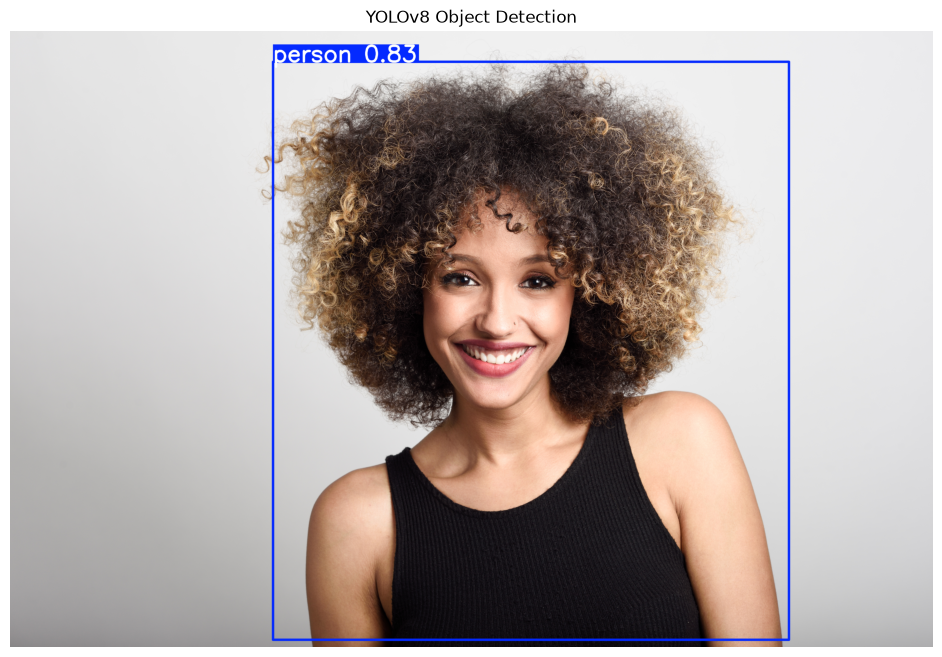

In [3]:
# TODO: Provide path to your YOLOv8 data.yaml
# - Ensure train/val image directories and class names are correct
# Get annotated image
annotated_image = results[0].plot()

# Convert BGR to RGB
annotated_image = cv2.cvtColor(
    annotated_image,
    cv2.COLOR_BGR2RGB
)

# Display image
plt.figure(figsize=(12, 8))

plt.imshow(annotated_image)
plt.title("YOLOv8 Object Detection")
plt.axis('off')

plt.show()

In [4]:
# TODO: Train YOLOv8 for a few epochs (e.g., 3)
# - Save the path to best weights (runs/detect/train*/weights/best.pt)
# Get detection information
result = results[0]

for box in result.boxes:

    class_id = int(box.cls[0])
    confidence = float(box.conf[0])

    class_name = yolo_model.names[class_id]

    print(
        f"Object: {class_name}, "
        f"Confidence: {confidence:.2f}"
    )

Object: person, Confidence: 0.83


In [5]:
# TODO: Run predictions with the trained YOLO model and visualize
# - Pick one or more images and display bounding boxes/labels
# Get detection information
result = results[0]

for box in result.boxes:

    class_id = int(box.cls[0])
    confidence = float(box.conf[0])

    class_name = yolo_model.names[class_id]

    print(
        f"Object: {class_name}, "
        f"Confidence: {confidence:.2f}"
    )

Object: person, Confidence: 0.83


### Reflection
- Are the predictions what you expected?
- If performance is weak, why? (data size/quality, epochs, augmentations, etc.)
- What would you adjust for a more serious training run?
- What other arguments can you use for the training function.